C:\Users\DileeP Kumar\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Sample rate: 44100, Duration: 18.10 seconds


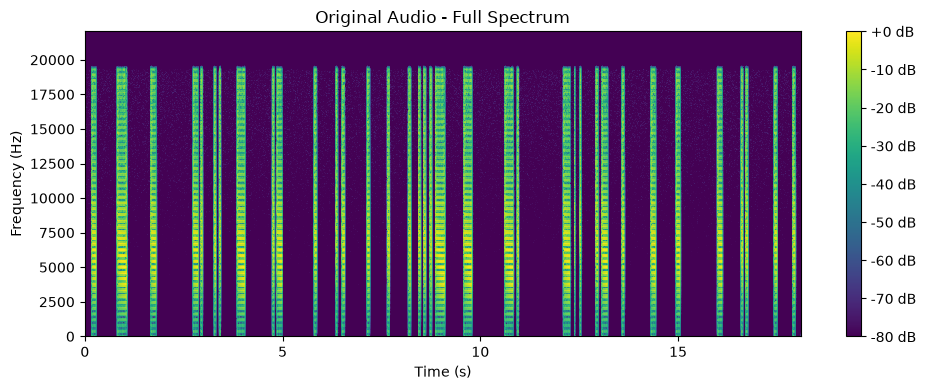

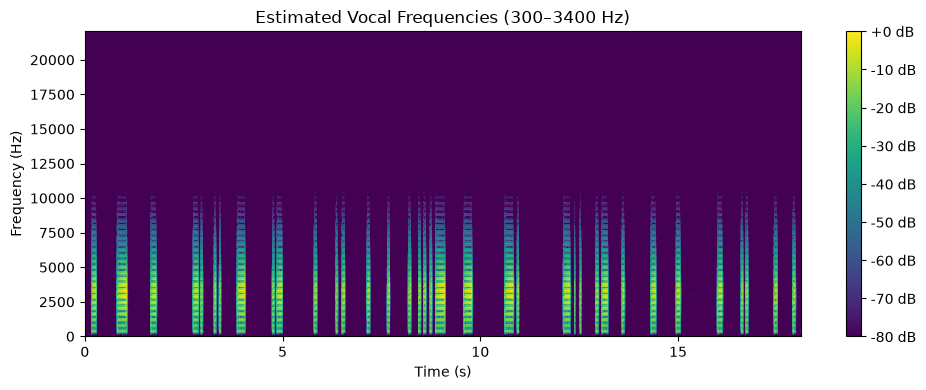

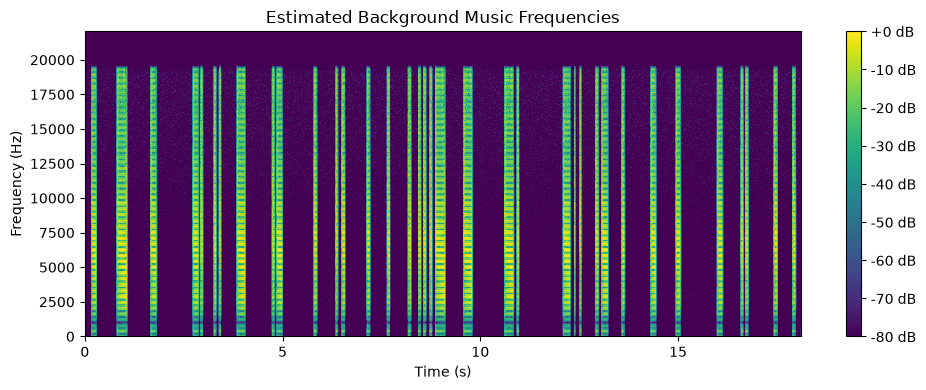

In [3]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import butter, lfilter

# --- 1. Load Audio File ---
filename = r"C:\Users\DileeP Kumar\Downloads\kave_msri-flickering-neon-316717.mp3"
y, sr = librosa.load(filename, sr=None)
print(f"Sample rate: {sr}, Duration: {len(y)/sr:.2f} seconds")

# --- 2. Bandpass Filter for Vocals (Speech: 300–3400 Hz) ---
def butter_bandpass(lowcut, highcut, fs, order=6):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return b, a

def bandpass_filter(data, lowcut, highcut, fs, order=6):
    b, a = butter_bandpass(lowcut, highcut, fs, order)
    return lfilter(b, a, data)

vocal_band = bandpass_filter(y, lowcut=300, highcut=3400, fs=sr)
background_band = y - vocal_band  # Approximation: remaining frequencies as background

# --- 3. Display Spectrograms (STFT) ---
def plot_spectrogram(signal, sr, title):
    D = librosa.amplitude_to_db(np.abs(librosa.stft(signal)), ref=np.max)
    plt.figure(figsize=(10, 4))
    librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='hz', cmap='viridis')
    plt.colorbar(format='%+2.0f dB')
    plt.title(title)
    plt.xlabel('Time (s)')
    plt.ylabel('Frequency (Hz)')
    plt.tight_layout()
    plt.show()

plot_spectrogram(y, sr, 'Original Audio - Full Spectrum')
plot_spectrogram(vocal_band, sr, 'Estimated Vocal Frequencies (300–3400 Hz)')
plot_spectrogram(background_band, sr, 'Estimated Background Music Frequencies')

# --- 4. Optional: Save Filtered Audio ---
sf.write('filtered_vocals.wav', vocal_band, sr)
sf.write('estimated_background.wav', background_band, sr)




In [2]:
pip install librosa soundfile matplotlib scipy

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   -------------- ------------------------- 1.0/2.8 MB 4.6 MB/s eta 0:00:01
   ------------------------------------- -- 2.6/2.8 MB 6.9 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 5.0 MB/s  0:00:00
   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
   -- ------------------------------------- 2.9/41.9 MB 10.5 MB/s eta 0:00:04
   ----- ---------------------------------- 5.2/41.9 MB 9.4 MB/s eta 0:00:04
   ------- -------------------------------- 7.3/41.9 MB 7.7 MB/s eta 0:00:05
   -------- ------------------------------- 8.7/41.9 MB 7.4 MB/s eta 0:00:05
   --------- ------------------------------ 10.0/41.9 MB 7.2 MB/s eta 0:00:05
   ---------- ----------------------------- 11.3/41.9 MB 7.1 MB/s eta 0:00:05
   ------------ --------------------------- 12.6/41.9 MB 6.9 MB/s eta 0:00:05
   ------------